# 3. Polishing the tree and ancestral states

After the fit, HERACLES can do three more things with the same edit model:

1. Score each branch of the tree by how well the embedding supports it.
2. Polish the tree with nearest-neighbour interchanges (NNI) that raise the
   likelihood of the whole tree.
3. Infer the character states of every ancestor and place each edit on a
   branch.

It uses the dataset from tutorial 1 and takes about five minutes on a
laptop CPU.

In [1]:
import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from heracles import Heracles, robinson_foulds, sokal_collapse

# HERACLES logs every fit to stderr and to heracles.log in the output folder.
# Keep only warnings here so the notebook stays readable.
logging.getLogger("heracles").setLevel(logging.WARNING)
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

DATA = Path("data")
RUNS = Path("runs")
RUNS.mkdir(exist_ok=True)
# Tutorial 1 explains this warning; hide it here.
warnings.filterwarnings("ignore", message="the loss was still improving")

from heracles.polish.ancestral import call_states, infer_ancestral_states
from heracles.polish import branch_support, model_rates
from heracles.trees.utils import copy_tree

`rf_to_truth` collapses a tree and the true tree the same way and returns
their Robinson-Foulds distance.

In [2]:
def rf_to_truth(tree, cm, truth_path):
    """RF distance (count, normalised) to the true tree, both Camin-Sokal collapsed."""
    truth = sokal_collapse(Path(truth_path).read_text(), cm)
    tree = sokal_collapse(tree, cm)
    return robinson_foulds(tree, truth), robinson_foulds(tree, truth, normalized=True)

In [3]:
cm = pd.read_csv(DATA / "cas9_mixed_dropout" / "characters.csv", index_col=0)
truth_path = DATA / "cas9_mixed_dropout" / "true_tree.nwk"

model = Heracles(outdir=RUNS / "polish", seed=0)
model.fit(cm)
rf, nrf = rf_to_truth(model.trees_["nj"], cm, truth_path)
print(f"before polishing: RF = {rf}, normalised RF = {nrf:.3f}")

before polishing: RF = 111, normalised RF = 0.259


## Branch support

`branch_support` gives each internal branch of a tree a score between 0 and
1. For a branch above clade C it samples quartets of cells, two inside C and
two among the nearest cells outside it, and records how often the embedding
distances group the quartet the way the branch does.

Because we know the true tree here, we can sort the branches of the binary
NJ tree into three groups: branches in the true tree, wrong branches that
survive the Camin-Sokal collapse, and branches that no edit supports (the
ones the collapse removes).

In [4]:
def splits(tree):
    """Each internal branch of a tree as a set of leaf labels, ignoring the root side."""
    leaves = {leaf.taxon.label for leaf in tree.leaf_nodes()}
    ref = min(leaves)
    out = {}
    for node in tree.preorder_internal_node_iter():
        if node.parent_node is None:
            continue
        clade = frozenset(leaf.taxon.label for leaf in node.leaf_iter())
        out[node] = clade if ref not in clade else frozenset(leaves - clade)
    return out


tree = model.trees_["nj"]
support = branch_support(tree, model.full_dists_, model.labels_)
true_splits = set(splits(sokal_collapse(truth_path.read_text(), cm)).values())
kept_splits = set(splits(model.trees_["nj_collapsed"]).values())

def group(split):
    if split in true_splits:
        return "in true tree"
    return "wrong, kept by collapse" if split in kept_splits else "no edit (collapsed)"

table = pd.DataFrame([{"support": support[node], "branch": group(split)}
                      for node, split in splits(tree).items() if node in support]).dropna()
table.groupby("branch")["support"].describe()[["count", "mean", "min", "max"]]

,count,mean,min,max
branch,,,,
in true tree,161.0,0.991587,0.653333,1.0
no edit (collapsed),35.0,0.953674,0.661972,1.0
"wrong, kept by collapse",52.0,0.973079,0.723232,1.0


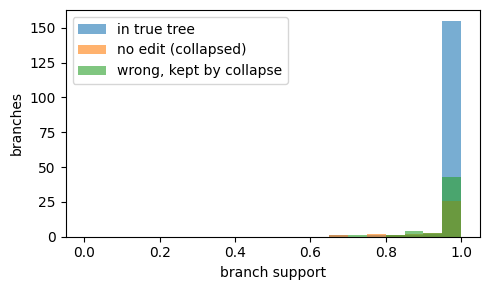

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
bins = np.linspace(0, 1, 21)
for name, values in table.groupby("branch")["support"]:
    ax.hist(values, bins=bins, alpha=0.6, label=name)
ax.set_xlabel("branch support")
ax.set_ylabel("branches")
ax.legend()
fig.tight_layout()

Wrong branches and branches that no edit supports have lower support on average (means of approximately 0.97 and 0.95, against 0.99 for branches in the true tree), but the ranges overlap: wrong branches score up to 1.0 and true ones as low as about 0.65. Support is a hint about where the tree is uncertain, not a filter, so the polish below tries moves around every branch rather than only the weakly supported ones.

## Likelihood NNI polish

`model.polish()` tries NNI moves around the branches of a read-out tree and
keeps each move that raises the log-likelihood of the character matrix
under the fitted edit model. It adds `nj_polished` and
`nj_polished_collapsed` to `model.trees_` and writes them to `outdir`. On
the command line this is `heracles polish characters.csv --model
runs/polish/model.npz`.

In [6]:
result = model.polish(cm)
print(f"{len(result.moves)} moves accepted in {result.n_rounds} rounds")
print(f"log-likelihood {result.loglik_start:.1f} -> {result.loglik_end:.1f}")

rows = []
for name, tree in [("HERACLES", model.trees_["nj"]),
                   ("HERACLES, polished", model.trees_["nj_polished"]),
                   ("NJ (starting tree)", model.diagnostics_["init_tree_newick"])]:
    rf, nrf = rf_to_truth(tree, cm, truth_path)
    rows.append({"method": name, "RF": rf, "normalised RF": round(nrf, 3)})
pd.DataFrame(rows).set_index("method")

15 moves accepted in 3 rounds
log-likelihood -8549.6 -> -8470.6


,RF,normalised RF
method,,
HERACLES,111,0.259
"HERACLES, polished",106,0.243
NJ (starting tree),161,0.384


## Ancestral states

The polished tree has maximum-likelihood branch lengths, so we can run
Felsenstein pruning on it to get the posterior over the state of every
site at every ancestor. `infer_ancestral_states` takes the fitted rates
from the model; it relabels the internal nodes `nd0, nd1, ...`, so we pass
it a copy.

`call_states` turns the posteriors into one state per node and site, and
sets calls below a confidence threshold (default 0.5) to `-1`.

In [7]:
tree = copy_tree(model.trees_["nj_polished"])
anc = infer_ancestral_states(tree, cm, allele_prior=model.config.allele_prior,
                             root_edge_length=result.root_edge_length,
                             **model_rates(model))
calls, _ = call_states(anc)
print(f"log-likelihood {anc.loglik:.1f}, {len(anc.node_labels)} nodes x {calls.shape[1]} sites")

log-likelihood -6901.6, 499 nodes x 30 sites


An edit happened on a branch if the parent is called unedited (`0`) and the
child carries an edit. Listing the branches with the most edits shows which
edits define the large clades.

In [8]:
row = {label: i for i, label in enumerate(anc.node_labels)}

def node_label(node):
    return node.taxon.label if node.is_leaf() else node.label

edges = []
for node in tree.preorder_node_iter():
    parent = node.parent_node
    if parent is None:
        continue
    p, c = calls[row[node_label(parent)]], calls[row[node_label(node)]]
    new = np.flatnonzero((p == 0) & (c > 0))
    edges.append({"clade size": sum(1 for _ in node.leaf_iter()),
                  "edits": len(new),
                  "site:allele": ", ".join(f"{anc.site_names[s]}:{c[s]}" for s in new)})

edges = pd.DataFrame(edges)
print(f"{edges['edits'].sum()} edits placed on {(edges['edits'] > 0).sum()} of {len(edges)} branches")
edges[edges["clade size"] > 1].sort_values(["clade size"], ascending=False).head(8)

773 edits placed on 333 of 498 branches


,clade size,edits,site:allele
237,131,4,"site8:10, site24:16, site26:21, site27:4"
0,119,4,"site1:3, site5:11, site18:1, site23:4"
100,69,6,"site7:13, site12:3, site13:2, site17:12, site2..."
238,66,3,"site4:1, site6:15, site12:3"
369,65,2,"site17:8, site25:12"
1,50,2,"site20:4, site27:8"
407,46,0,
409,45,0,


`anc.posteriors` holds the full posterior for each node and site, and
`heracles.polish.ancestral.optimize_branch_lengths` refits the branch lengths of
any tree under the same model.

**Next:** [4. Sequential recorders](04_sequential_recorders.ipynb).